# Generate plots of Radio Sources Occultation based on ExPRES simulations during Galileo C09 flyby of Callisto

This notebook reads the C09 flyby ephemeris, and the ExPRES CDF file of simulates radio sources, then creates synthesized dynamic spectrum of the occulted radio sources

## Workflow



In [1]:
import occultation

from pathlib import Path
import importlib
import json

from matplotlib import pyplot as plt
%matplotlib inline
import matplotlib.dates as mdates
ticks_30min = mdates.MinuteLocator(interval=30)
ticks_10min = mdates.MinuteLocator(interval=10)
dateFmt = mdates.DateFormatter('%H:%M')


current_dir = Path.cwd().resolve()
root_path = next(
    (path for path in (current_dir, *current_dir.parents)
     if (path / "Tutorial_1.ipynb").is_file()),
    None,
)
if root_path is None:
    raise FileNotFoundError(
        "Unable to find Tutorial_1.ipynb in the current directory "
        f"or its parents ({current_dir})."
    )

from cosmographia_utils import load_mission_config

/Users/clouis/anaconda3/envs/expres-occultation/lib/python3.9/site-packages/spacepy/time.py:2448: UserWarning: Leapseconds may be out of date. Use spacepy.toolbox.update(leapsecs=True)
  _read_leaps()


In [2]:
Spacecraft_name = 'GLL'
flyby_name = 'C09'

## Loading and Reading CDF file

The code will ask you to enter the full path and name of the ExPRES CDF containing source positions

In [3]:
cdf_file_path = "data/expres-simulations/C09/expres_gll_jupiter_0d-30r_jrm09_lossc-wid1deg_5kev_19970625_v11.cdf"
if not Path(cdf_file_path).is_file():
    raise FileNotFoundError(f"ExPRES CDF not found: {cdf_file_path}")


In [4]:
frequency_to_look_at = 5.0 # in MHz

/Users/clouis/anaconda3/envs/expres-occultation/lib/python3.9/site-packages/numpy/linalg/linalg.py:2582: RuntimeWarning: overflow encountered in multiply
  s = (x.conj() * x).real


(241, 42, 722)
0.009374531031508452
0.18535532699753918
this is the distance to the flyby target


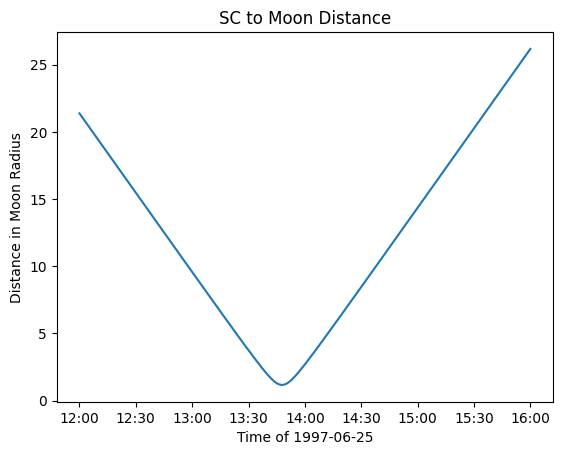

this is the distance to the radio sources


/Users/clouis/anaconda3/envs/expres-occultation/lib/python3.9/site-packages/numpy/ma/core.py:6980: RuntimeWarning: overflow encountered in power
  result = np.where(m, fa, umath.power(fa, fb)).view(basetype)


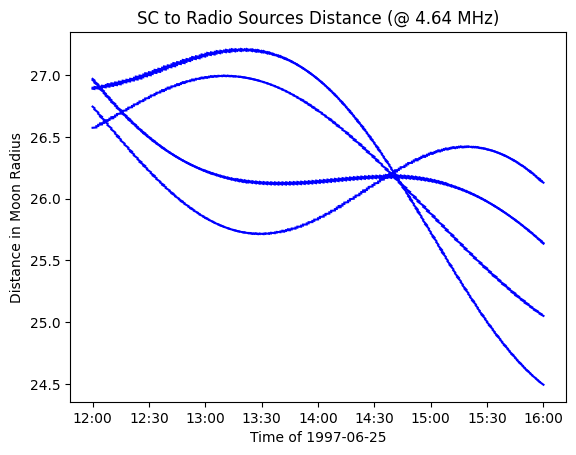

this is the intercept distance at the default 
 If a line goes below 1 
 if the line is blue there should be an occultation 
 if the line is grey the spacecraft is located in-between the sources and the moon


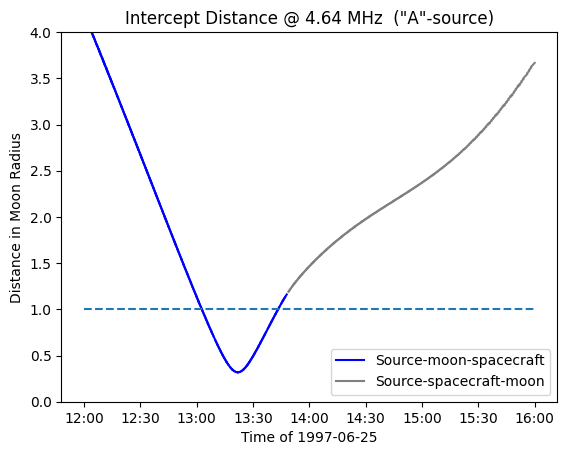

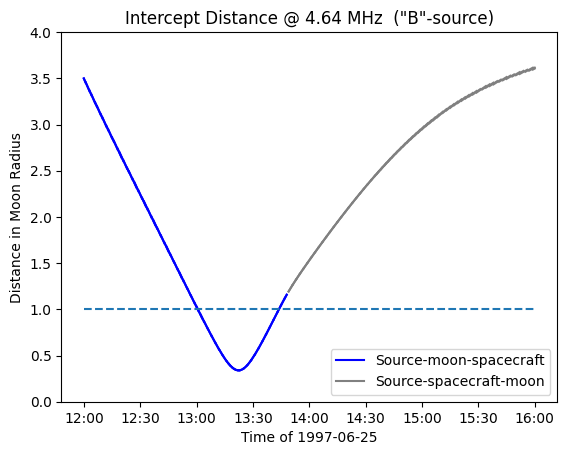

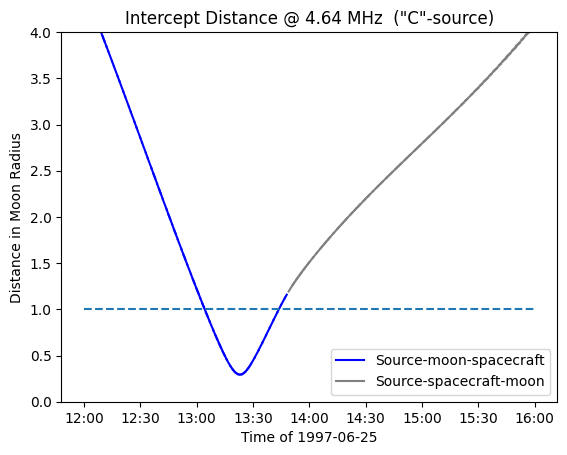

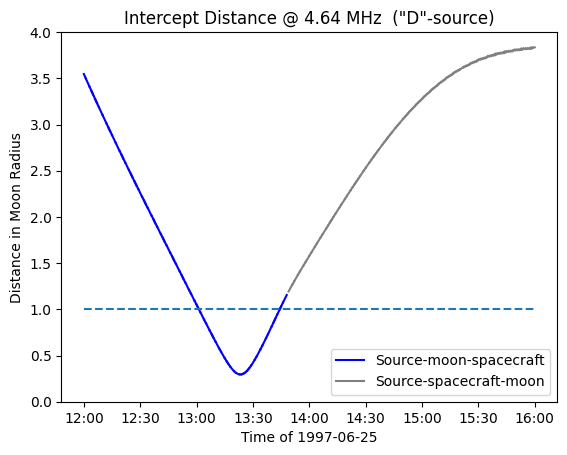

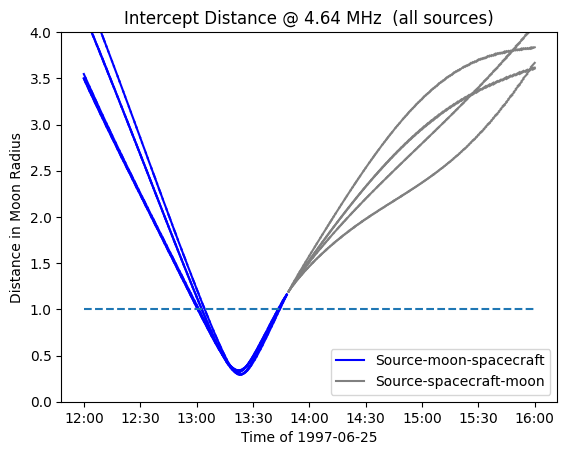

10122
(241, 42)
The occultation radius is set to 1.0 (1 = no atmosphere)
1.0 5157.0
1.0 5658.0


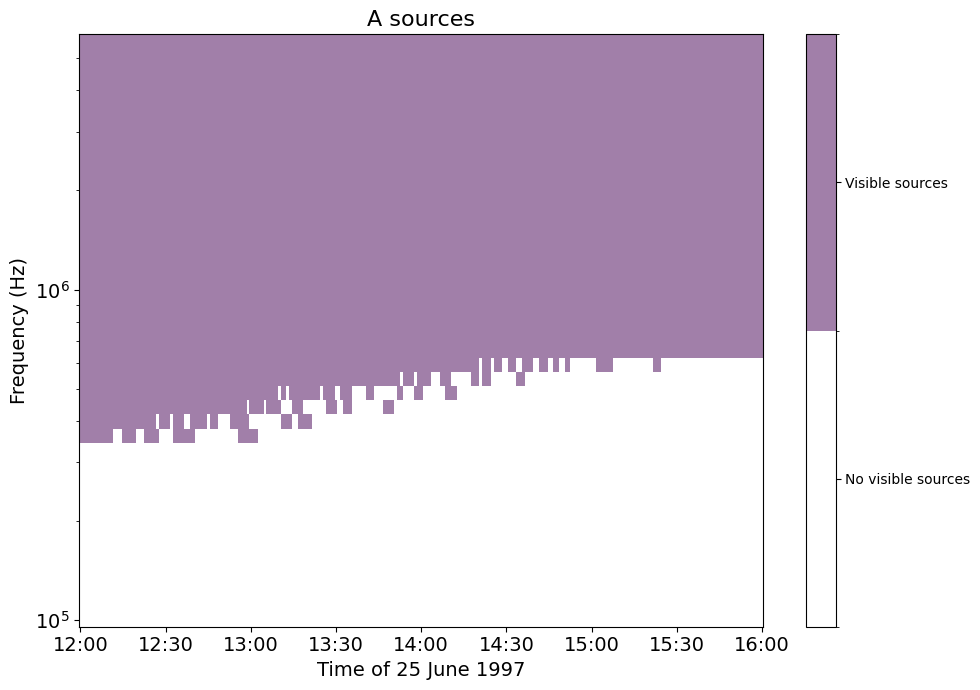

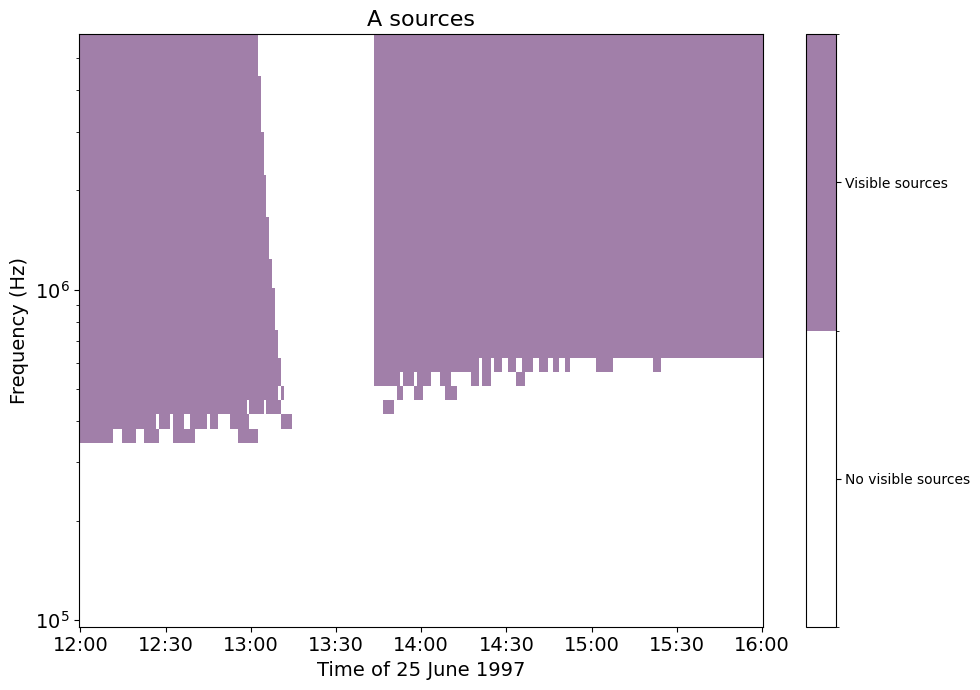

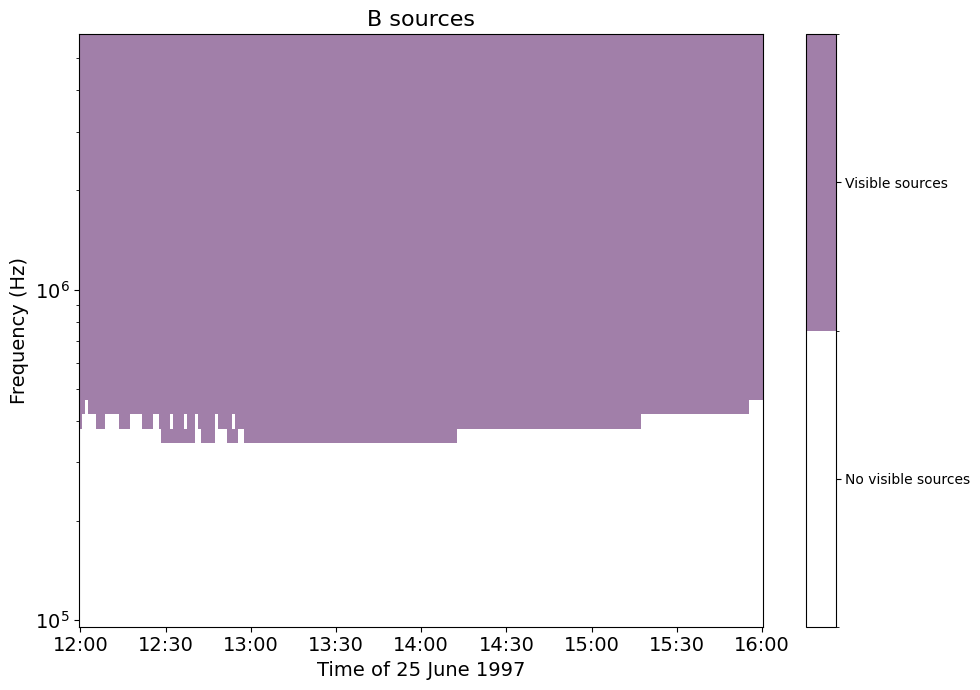

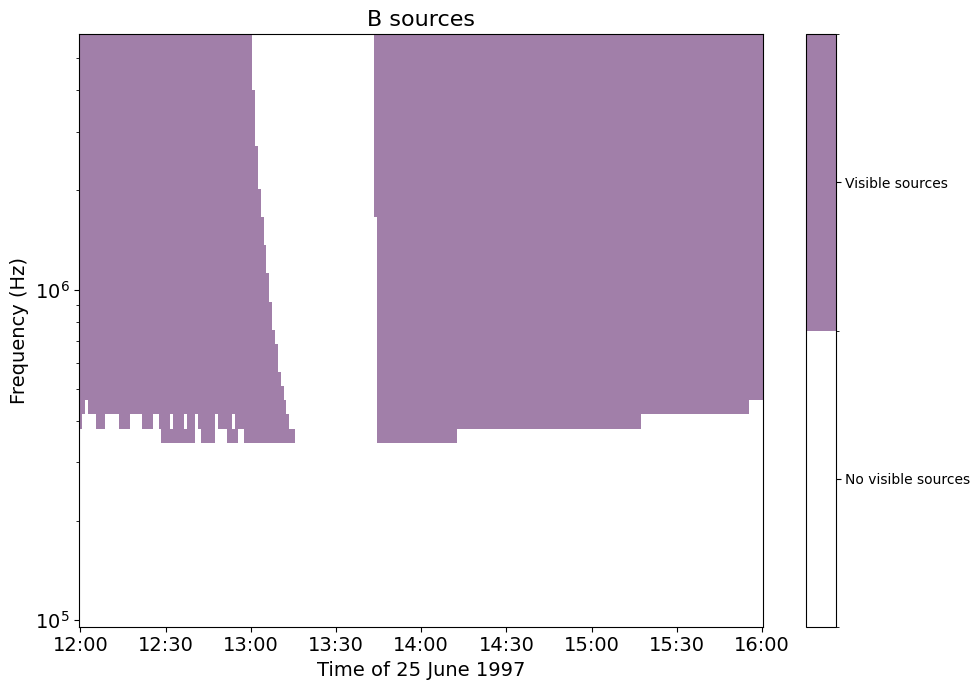

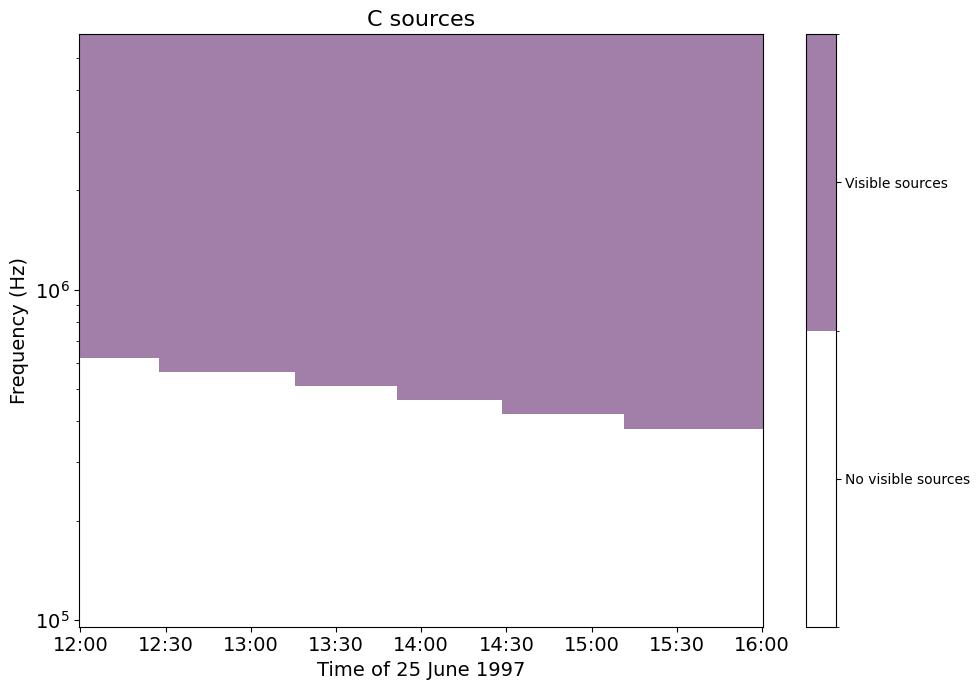

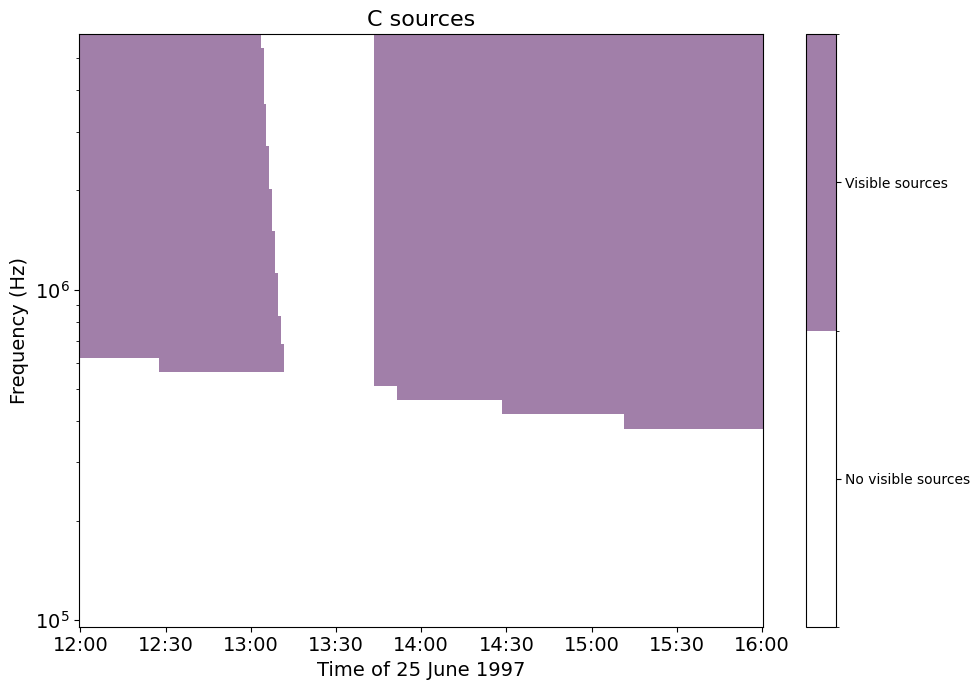

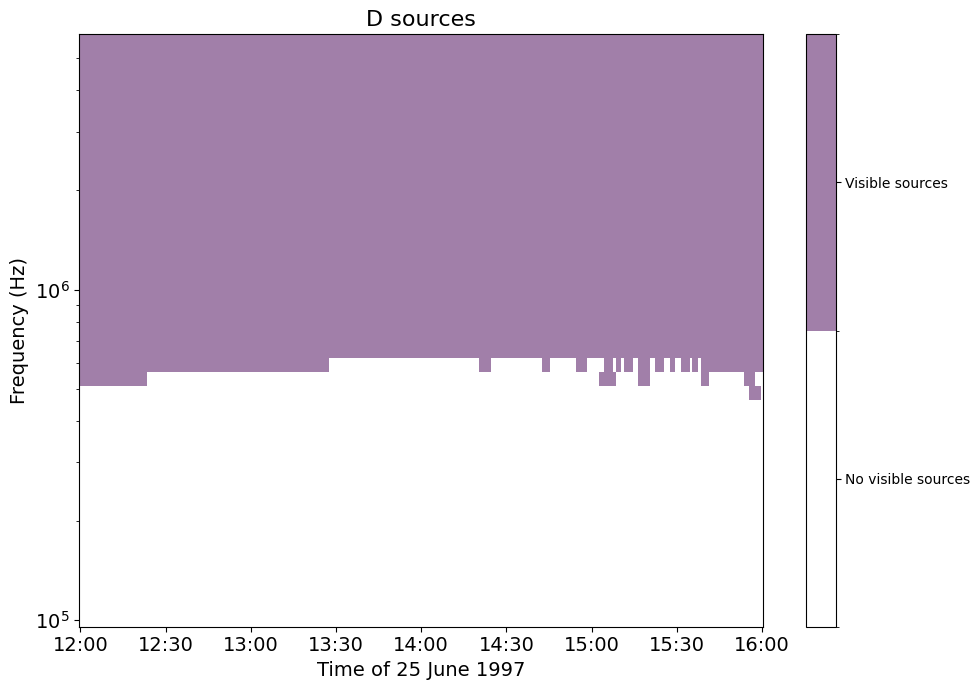

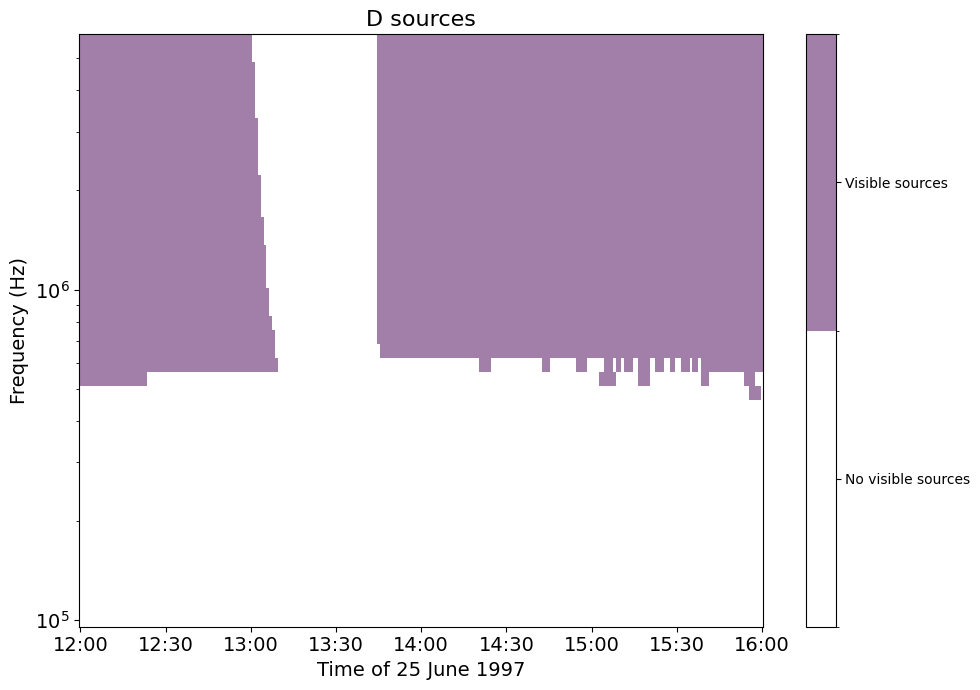

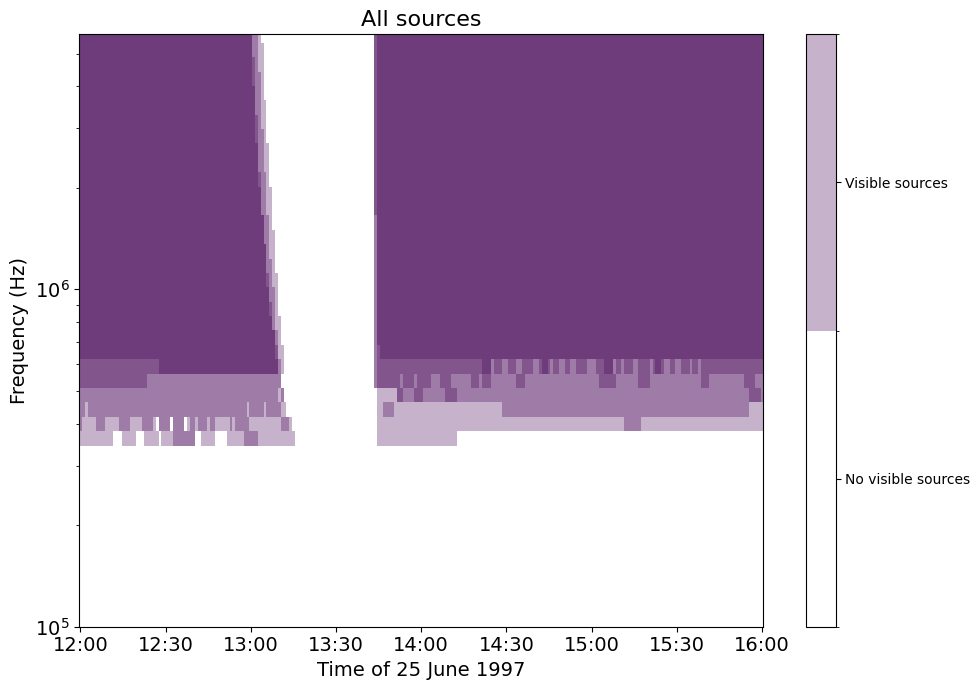

(datetime.datetime(1997, 6, 25, 12, 0), datetime.datetime(1997, 6, 25, 16, 0))


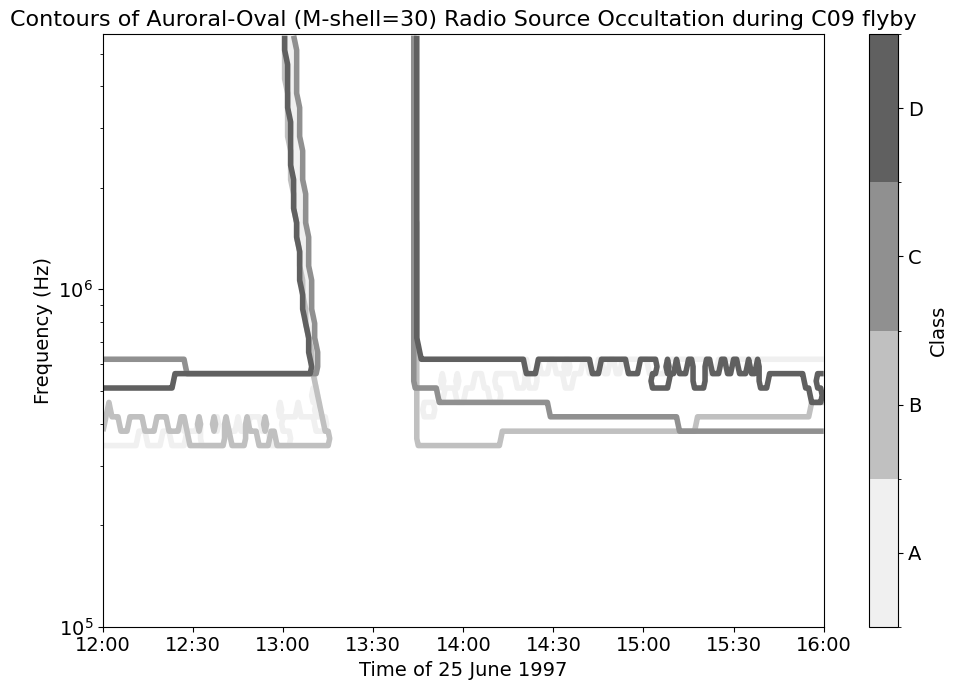

In [5]:
occultation = importlib.reload(occultation)
occultation.full_plots(flyby_name, expres_file=cdf_file_path, frequency_to_look_at = frequency_to_look_at)